# Laboratorium 1: dobór struktury produkcji i alokacja zasobów w PuLP

[![Otwórz w Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdoHaha/automation_robotics_lab/blob/master/pl/lab_auto_1.ipynb)

**Pytanie:** jak mała fabryka zestawów robotycznych powinna podzielić ograniczony czas montażu i testowania?

W laboratorium 0 poznaliśmy słowniki, funkcje, tabele, wykresy i suwaki Pythona. Teraz użyjemy tych narzędzi w eksperymencie optymalizacyjnym. Zbudujesz model, zinterpretujesz go i przedstawisz rekomendację.

Po wykonaniu ćwiczeń potrafisz rozpoznać **parametry, zmienne decyzyjne, funkcję celu, ograniczenia, zbiór rozwiązań dopuszczalnych, luz ograniczenia, ograniczenia aktywne i ceny dualne (ceny cienia)**; odróżnić LP od modelu całkowitoliczbowego i zbudować suwak, który ponownie rozwiązuje model oraz rysuje wynik po zmianie założenia.

Przejdź przez opis sytuacji i obliczenia ręczne, pierwszy model PuLP, geometrię i luz ograniczeń, a następnie wykresy, eksperymenty interaktywne, analizę wrażliwości i rekomendację. Porównanie produkcji całych zestawów jest częścią główną; koszty zredukowane stanowią opcjonalne rozszerzenie.

W Colab zapisz własną kopię przez **File → Save a copy in Drive** (**Plik → Zapisz kopię na Dysku**), a następnie wybierz **Runtime → Run all** (**Środowisko wykonawcze → Uruchom wszystko**). Wszystkie dane dydaktyczne są zawarte w notebooku. Internet jest potrzebny raz do instalacji pakietów; przykłady nie wymagają klonowania repozytorium, podłączania Dysku ani pobierania CSV. W świeżym środowisku uruchamiaj komórki od góry. Jeśli kontrolki się nie wyświetlają, korzystaj z sąsiednich komórek parametrów.

## 0. Przygotowanie środowiska

PuLP opisuje model optymalizacyjny, a dołączony solver CBC oblicza rozwiązanie. Korzystamy z PuLP 3.x, ponieważ notebooki kursu pokazują interfejs modelowania tej wersji. Matplotlib rysuje wykresy, pandas tworzy tabele, a ipywidgets łączy kontrolki z Pythonem.

In [1]:
# Zainstaluj pakiety w kernelu tego notebooka, zachowując ten sam interfejs modelowania w Colab.
%pip install -q "pulp>=3.3,<4" numpy pandas matplotlib ipywidgets
%matplotlib inline

import pulp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass  # Lokalny Jupyter nie potrzebuje menedżera kontrolek Colab.

SOLVER = pulp.PULP_CBC_CMD(msg=False)
if not SOLVER.available():
    raise RuntimeError("Brakuje CBC. Uruchom ponownie przygotowanie w świeżym środowisku Colab.")
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": False})
print("PuLP", pulp.__version__, "| CBC dostępny")

PuLP 3.3.2 | CBC dostępny


## 1. Sytuacja: dwa zestawy i dwa wspólne stanowiska

Fabryka sprzedaje edukacyjne zestawy robotyczne **Mini** i **Pro**. Dziennie dysponuje 350 minutami montażu i 180 minutami testowania. Zakładamy nieograniczony popyt, stały jednostkowy wkład do zysku i brak strat czasu na przezbrojenia. Poniższe współczynniki to **przykładowe dane dydaktyczne**, nie oferty handlowe.

| Produkt | Zysk (PLN/zestaw) | Montaż (min/zestaw) | Testowanie (min/zestaw) |
|:--|--:|--:|--:|
| Mini | 40 | 20 | 15 |
| Pro | 70 | 40 | 10 |

Pierwszy model traktuje produkcję jako **podzielną wielkość planistyczną**; ułamkowe zestawy reprezentują średnią dzienną produkcję w wielu dniach. Jeśli dziś mamy wyprodukować całe zestawy, rozwiążemy model całkowitoliczbowy.

W kodzie, tabelach i nazwach ograniczeń zachowujemy wspólne identyfikatory: `Assembly` oznacza montaż, `Testing` — testowanie, a Mini i Pro są nazwami produktów. Angielskie nazwy kolumn, np. `used_min` i `slack_min`, pozwalają używać tych samych obliczeń w obu wersjach językowych; oznaczają odpowiednio zużyte minuty i luz ograniczenia w minutach.

,profit_PLN_per_kit,assembly_min_per_kit,testing_min_per_kit
Mini,40.0,20.0,15.0
Pro,70.0,40.0,10.0


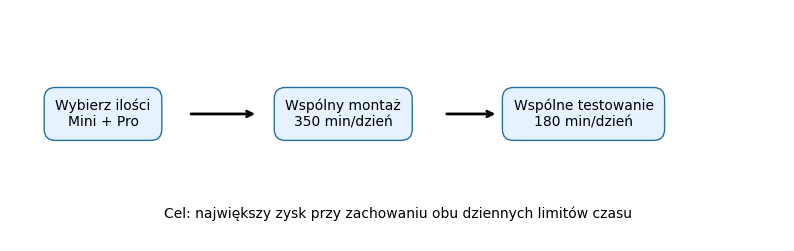

In [2]:
# Zapisz dane sytuacji jako wielokrotnie używane parametry produktów, zysku, czasu i limitów.
PRODUCTS = ["Mini", "Pro"]
PROFIT = {"Mini": 40.0, "Pro": 70.0}
TIME = {
    "Assembly": {"Mini": 20.0, "Pro": 40.0},
    "Testing": {"Mini": 15.0, "Pro": 10.0},
}
CAPACITY = {"Assembly": 350.0, "Testing": 180.0}
data = pd.DataFrame({
    "profit_PLN_per_kit": PROFIT,
    "assembly_min_per_kit": TIME["Assembly"],
    "testing_min_per_kit": TIME["Testing"],
})
display(data)

fig, ax = plt.subplots(figsize=(10, 3))
ax.axis("off")
boxes = [(0.12, "Wybierz ilości\nMini + Pro"),
         (0.43, "Wspólny montaż\n350 min/dzień"),
         (0.74, "Wspólne testowanie\n180 min/dzień")]
for x_pos, label in boxes:
    ax.text(x_pos, 0.55, label, ha="center", va="center", transform=ax.transAxes,
            bbox=dict(boxstyle="round,pad=0.8", fc="#e6f2ff", ec="#2471a3"))
for x_start, x_end in [(0.23, 0.32), (0.56, 0.63)]:
    ax.annotate("", xy=(x_end, 0.55), xytext=(x_start, 0.55),
                xycoords="axes fraction", arrowprops=dict(arrowstyle="->", lw=2))
ax.text(0.5, 0.10, "Cel: największy zysk przy zachowaniu obu dziennych limitów czasu",
        transform=ax.transAxes, ha="center")
plt.show()

### Zadanie 1 — przewidź wynik przed rozwiązaniem modelu

DO ZROBIENIA: oblicz zużycie czasu i zysk dla `(Mini, Pro) = (10, 0), (0, 8), (5, 6), (8, 5)`. Które plany są dopuszczalne? Dlaczego wybieranie wyłącznie zestawu o największym zysku jednostkowym może zawieść? Porównaj **zysk na minutę montażu** i **zysk na minutę testowania**: czy oba rankingi są takie same? Zapisz przewidywaną najlepszą strukturę produkcji przed kolejną komórką.

In [3]:
# Sprawdź ręcznie wybrane plany, zanim poprosisz solver o wybór najlepszego.
candidates = [(10, 0), (0, 8), (5, 6), (8, 5)]
candidate_rows = []
for mini, pro in candidates:
    assembly = 20 * mini + 40 * pro
    testing = 15 * mini + 10 * pro
    candidate_rows.append({
        "Mini": mini, "Pro": pro,
        "assembly_min": assembly, "testing_min": testing,
        "profit_PLN": 40 * mini + 70 * pro,
        "feasible": assembly <= 350 and testing <= 180,
    })
display(pd.DataFrame(candidate_rows))

,Mini,Pro,assembly_min,testing_min,profit_PLN,feasible
0,10,0,200,150,400,True
1,0,8,320,80,560,True
2,5,6,340,135,620,True
3,8,5,360,170,670,False


## 2. Zapisz sytuację jako program liniowy

**Parametr** to znana dana wejściowa (350 minut); **zmienna decyzyjna** to niewiadoma wybierana przez solver ($m$ zestawów Mini i $p$ zestawów Pro). **Funkcja celu** mierzy jakość decyzji. **Ograniczenie** opisuje regułę, którą musi spełniać każda dopuszczalna decyzja.

$$\max\; Z = 40m + 70p\quad\text{PLN/dzień}$$
$$20m + 40p \le 350\quad\text{min montażu/dzień}$$
$$15m + 10p \le 180\quad\text{min testowania/dzień},\qquad m,p\ge0.$$

Każdy składnik mnoży **stałą** przez jedną zmienną. Na przykład `(min/zestaw) × (zestawy/dzień) = min/dzień`. Iloczyny decyzji, takie jak $mp$, nie są liniowe. Model zakłada sumowanie czasu i zysku, stałe współczynniki i podzielne ilości.

**Zbiór rozwiązań dopuszczalnych** zawiera wszystkie decyzje spełniające każde ograniczenie. **Rozwiązanie optymalne** to decyzja dopuszczalna o najlepszej wartości funkcji celu. Ograniczony problem LP z niepustym zbiorem rozwiązań dopuszczalnych ma optimum w wierzchołku; wiele rozwiązań optymalnych może też leżeć wzdłuż krawędzi.

### Zbuduj pierwszy model krok po kroku

`LpProblem` określa maksymalizację lub minimalizację. `LpVariable` ustala granice i kategorię zmiennej. Pierwsze poniższe `model += expression` to funkcja celu; wyrażenia z `<=`, `>=` lub `==` są ograniczeniami. Nazwy ułatwiają sprawdzanie wierszy modelu. `lpSum` pozwoli uogólnić ten zapis na wiele produktów.

In [4]:
# Zdefiniuj nieujemne ilości ciągłe, a następnie dodaj zysk i limity stanowisk.
first_model = pulp.LpProblem("first_product_mix", pulp.LpMaximize)
mini = pulp.LpVariable("Mini", lowBound=0, cat="Continuous")
pro = pulp.LpVariable("Pro", lowBound=0, cat="Continuous")

first_model += 40 * mini + 70 * pro, "daily_profit"
first_model += 20 * mini + 40 * pro <= 350, "Assembly"
first_model += 15 * mini + 10 * pro <= 180, "Testing"
print(first_model)

first_product_mix:
MAXIMIZE
40*Mini + 70*Pro + 0
SUBJECT TO
Assembly: 20 Mini + 40 Pro <= 350

Testing: 15 Mini + 10 Pro <= 180

VARIABLES
Mini Continuous
Pro Continuous



### Najpierw status, potem liczby

**Optimal:** znaleziono najlepsze rozwiązanie dopuszczalne. **Infeasible:** ograniczenia są sprzeczne. **Unbounded:** funkcja celu może poprawiać się bez ograniczenia (często brakuje ograniczenia). **Not Solved/Undefined:** nie należy deklarować optimum. Wartości zmiennych pozostawione po nieudanym rozwiązaniu nie tworzą użytecznego planu produkcji. Zachowujemy angielskie statusy, ponieważ takie wartości zwraca PuLP.

In [5]:
# Rozwiąż model; odczytuj ilości i zysk dopiero przy statusie optymalnym.
first_model.solve(SOLVER)
first_status = pulp.LpStatus[first_model.status]
print("Status:", first_status)
if first_status == "Optimal":
    print(f"Mini = {mini.value():.3f}, Pro = {pro.value():.3f}")
    print(f"Zysk = {pulp.value(first_model.objective):.2f} PLN/dzień")
else:
    print("Sprawdź model przed użyciem wartości zmiennych.")

Status: Optimal
Mini = 9.250, Pro = 4.125
Zysk = 658.75 PLN/dzień


## 3. Funkcja rozwiązująca model w kolejnych eksperymentach

Buduj nowy model dla każdego scenariusza, aby zmiany suwaków nie dokładały kolejnych ograniczeń do poprzedniego modelu. Słownik tworzy po jednej zmiennej na produkt; pętla tworzy po jednym wierszu na zasób. `solve_product_mix(assembly_min=350, testing_min=180, pro_profit=70, minimum=None, integer=False)` przyjmuje dostępny czas stanowisk w minutach/dzień, zysk Pro w PLN/zestaw, opcjonalny słownik minimalnych zamówień w zestawach/dzień i przełącznik produkcji całych zestawów. Na przykład `solve_product_mix(testing_min=200, minimum={"Mini": 13})` zmienia tylko czas testowania i zamówienie Mini; pominięte argumenty zachowują wartości domyślne.

Funkcja sprawdza dane wejściowe, buduje zmienne i ograniczenia, rozwiązuje model, sprawdza status i weryfikuje wynik względem opisu sytuacji. Zwraca słownik: `status` i `model` oraz dane scenariusza, a dla optimum także `quantities`, `profit` i tabele `resources` oraz `variables`. Dla statusów innych niż optymalny te pola rozwiązania pozostają `None`. Korzysta ze wspólnych `PRODUCTS`, `TIME` i `SOLVER`, ale sama niczego nie wyświetla. Wspólna struktura wyników pozwala wykresom, suwakom i eksperymentom wrażliwości porównywać te same sprawdzone ilości bez budowania oddzielnych wersji modelu.

In [6]:
def solve_product_mix(assembly_min=350, testing_min=180,
                      pro_profit=70, minimum=None, integer=False):
    """Zoptymalizuj produkcję Mini/Pro dla scenariusza bez wyświetlania.

    assembly_min=350 i testing_min=180 to minuty/dzień; pro_profit=70
    podaje PLN na zestaw Pro. minimum=None oznacza brak wymaganych zamówień;
    w przeciwnym razie podaj słownik produktu i zestawów/dzień.
    integer=False dopuszcza podzielne ilości; True wymaga całych zestawów.
    Zysk Mini pozostaje równy 40 PLN/zestaw. Korzysta z globalnych
    PRODUCTS, TIME (min/zestaw) i SOLVER.

    Zwraca słownik zawierający status, model, capacities, profits, minimum
    i integer. Dla optimum zawiera też quantities (zestawy/dzień),
    profit (PLN/dzień), resources (zużycie i luz w minutach oraz ceny dualne LP)
    i variables (produkcja i koszty zredukowane LP); w innym przypadku None.
    Niepoprawne dane liczbowe lub nieznane produkty w zamówieniu dają ValueError.
    """
    # Sprawdź dane scenariusza przed utworzeniem modelu optymalizacyjnego.
    capacities = {"Assembly": float(assembly_min), "Testing": float(testing_min)}
    if any(not np.isfinite(v) or v < 0 for v in capacities.values()):
        raise ValueError("Limity czasu muszą być skończone i nieujemne.")
    if not np.isfinite(pro_profit):
        raise ValueError("Zysk musi być wartością skończoną.")
    minimum = {} if minimum is None else dict(minimum)
    if set(minimum) - set(PRODUCTS):
        raise ValueError("Nieznany produkt w minimalnych zamówieniach.")
    if any(not np.isfinite(v) or v < 0 for v in minimum.values()):
        raise ValueError("Minimalne zamówienia muszą być skończone i nieujemne.")

    # Zbuduj nowy model maksymalizacji: ilości, zysk, następnie limity stanowisk i zamówień.
    profits = {"Mini": 40.0, "Pro": float(pro_profit)}
    model = pulp.LpProblem("product_mix", pulp.LpMaximize)
    x = {product: pulp.LpVariable(product, lowBound=0,
                                  cat="Integer" if integer else "Continuous")
         for product in PRODUCTS}
    model += pulp.lpSum(profits[product] * x[product] for product in PRODUCTS), "profit"
    for resource in TIME:
        model += pulp.lpSum(TIME[resource][product] * x[product]
                            for product in PRODUCTS) <= capacities[resource], resource
    for product, amount in minimum.items():
        model += x[product] >= amount, f"minimum_{product}"
    # Rozwiąż model raz; inne statusy niż optymalny nie mogą dostarczać ilości do wykresu.
    model.solve(SOLVER)
    status = pulp.LpStatus[model.status]
    result = {"status": status, "model": model, "quantities": None, "profit": None,
              "resources": None, "variables": None, "capacities": capacities,
              "profits": profits, "minimum": minimum, "integer": integer}
    if status != "Optimal":
        return result

    # Zapisz optimum jako produkcję i niezależnie obliczone zużycie zasobów.
    quantities = {product: float(x[product].value()) for product in PRODUCTS}
    resource_rows = []
    for resource in TIME:
        used = sum(TIME[resource][product] * quantities[product] for product in PRODUCTS)
        slack = capacities[resource] - used
        resource_rows.append({
            "resource": resource, "used_min": used, "available_min": capacities[resource],
            "slack_min": slack, "binding": abs(slack) < 1e-6,
            "shadow_PLN_per_min": None if integer else model.constraints[resource].pi,
        })
    # Miary krańcowe LP podajemy tylko dla modelu ciągłego, nie dla całych zestawów.
    result.update({
        "quantities": quantities, "profit": float(pulp.value(model.objective)),
        "resources": pd.DataFrame(resource_rows).set_index("resource"),
        "variables": pd.DataFrame([
            {"product": product, "kits_per_day": quantities[product],
             "reduced_cost_PLN_per_kit": None if integer else x[product].dj}
            for product in PRODUCTS
        ]).set_index("product"),
    })
    # Sprawdź zgodność z opisem sytuacji, niezależnie od statusu solvera.
    assert all(v >= -1e-6 for v in quantities.values())
    assert all(row["slack_min"] >= -1e-5 for row in resource_rows)
    assert all(quantities[p] >= amount - 1e-6 for p, amount in minimum.items())
    if integer:
        assert all(abs(v - round(v)) < 1e-6 for v in quantities.values())
    return result

# Zachowaj jeden scenariusz domyślny do dalszych wykresów i porównań.
baseline = solve_product_mix()
display(baseline["variables"])
display(baseline["resources"])
print(f"Zysk wariantu bazowego: {baseline['profit']:.2f} PLN/dzień")

,kits_per_day,reduced_cost_PLN_per_kit
product,,
Mini,9.250,-0.0
Pro,4.125,-0.0


,used_min,available_min,slack_min,binding,shadow_PLN_per_min
resource,,,,,
Assembly,350.0,350.0,0.0,True,1.625
Testing,180.0,180.0,0.0,True,0.500


Zysk wariantu bazowego: 658.75 PLN/dzień


## 4. Luz, nadwyżka i ograniczenia aktywne

**Luz ograniczenia** to niewykorzystana część dopuszczalnej granicy górnej. Jeśli $a^Tx\le b$, luz wynosi $b-a^Tx$. Dla wymogu minimalnego $a^Tx\ge b$ **nadwyżka** wynosi $a^Tx-b$. Przy równości sprawdź resztę $a^Tx-b$: powinna być bliska zeru. Nieujemność również jest ograniczeniem: $m=0$ oznacza aktywną dolną granicę tej zmiennej.

Ograniczenie jest **aktywne**, gdy odstęp od granicy jest w przybliżeniu zerowy (stosujemy tolerancję numeryczną). Aktywność opisuje obecne rozwiązanie; nie oznacza automatycznie, że zakup większej ilości zasobu pomoże. **Cena dualna (cena cienia)** szacuje zmianę wartości funkcji celu na dodatkową jednostkę prawej strony ograniczenia w ciągłym LP, dopóki obecna baza optymalna pozostaje właściwa. Jest to lokalna miara, a nie obietnica dla dużej zmiany ani wartość krańcowa modelu całkowitoliczbowego.

### Zadanie 2 — zinterpretuj tabelę zasobów

DO ZROBIENIA: wskaż aktywne wiersze, wyjaśnij jednostki każdej kolumny i oblicz oba luzy ręcznie. Czy zerowy luz oznacza brak pozostałego czasu, czy brak wartości zasobu? Jak przedstawisz odstęp od granicy zamówienia typu `>=`?

## 5. Naucz się rysować: zacznij od wykresu zasobów

Figura to cały rysunek; `Axes` jest obszarem rysowania. `barh` przedstawia wartości na poziomym wykresie słupkowym; `left=used` dokłada niewykorzystany czas za czasem wykorzystanym. Opisy podają jednostki. `plt.show()` wyświetla figurę. Najpierw utwórz tabelę, a następnie narysuj te same wartości.

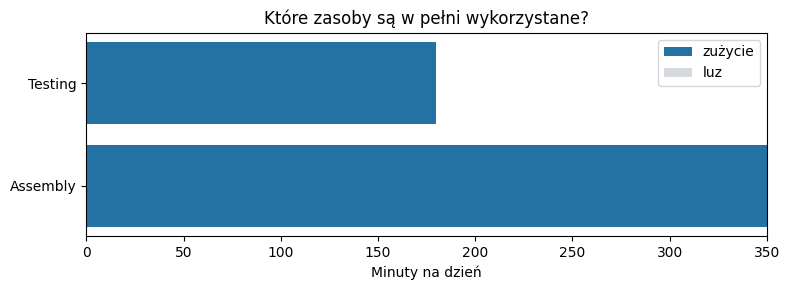

In [7]:
# Ułóż zużyte i niewykorzystane minuty z tej samej sprawdzonej tabeli zasobów.
resources = baseline["resources"]
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(resources.index, resources["used_min"], label="zużycie", color="#2471a3")
ax.barh(resources.index, resources["slack_min"], left=resources["used_min"],
        label="luz", color="#d5d8dc")
ax.set_xlabel("Minuty na dzień")
ax.set_title("Które zasoby są w pełni wykorzystane?")
ax.legend()
plt.tight_layout()
plt.show()

DO ZROBIENIA: skopiuj komórkę wykresu pod swoje notatki. Zmień kolory, dodaj wartości za pomocą `ax.text` i utwórz drugi wykres ilości Mini i Pro. Napisz, na jakie pytanie odpowiada każdy wykres.

### Obraz zbioru rozwiązań dopuszczalnych

Oś pozioma przedstawia produkcję Mini, a pionowa — produkcję Pro. Każda prosta jest limitem zasobu. Zacieniowany obszar spełnia **obie** nierówności i nieujemność. Kropkowana prosta funkcji celu przechodzi przez optimum; proste równoległe przedstawiają taki sam zysk. Taki rysunek działa dla dwóch zmiennych; tabele i wykresy zasobów działają również przy wielu zmiennych.

`plot_product_mix(result)` przyjmuje słownik zwracany przez `solve_product_mix`. Najpierw sprawdza `status`, oblicza obie proste graniczne, zacienia ich wspólny obszar z uwzględnieniem zamówień i zaznacza optimum. W trybie całych zestawów dodaje również dopuszczalne punkty całkowitoliczbowe. Drugi panel rysuje zużycie i luz z tabeli zasobów. Funkcja wyświetla figurę i zwraca `None`; nie rozwiązuje modelu ponownie ani nie zmienia wyniku. Użyj jej jako `plot_product_mix(solve_product_mix(assembly_min=800))`, aby porównać scenariusze przy tym samym znaczeniu osi. Współczynniki czasu i zysku używane do geometrii odpowiadają stałym danym naszego przykładu z dwoma produktami.

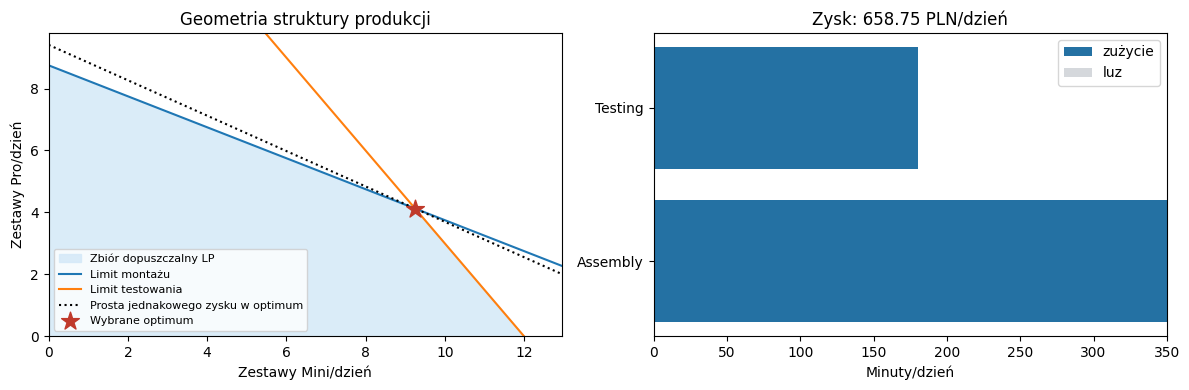

In [8]:
def plot_product_mix(result):
    """Wyświetl zbiór dopuszczalny i zużycie zasobów dla wyniku solvera.

    result to słownik z solve_product_mix: capacities w min/dzień,
    quantities w zestawach/dzień, profits w PLN/zestaw, minimum i integer.
    Status inny niż Optimal powoduje komunikat i zwrócenie None.
    Status Optimal wyświetla dwa panele Matplotlib i zwraca None;
    tryb integer dodaje dopuszczalne punkty produkcji całych zestawów.
    Korzysta z globalnych np, plt i stałych współczynników stanowisk
    naszego przykładu; nie wykonuje optymalizacji.
    """
    # Odrzuć niepoprawne pola rozwiązania przed obliczeniami geometrycznymi.
    if result["status"] != "Optimal":
        print("Brak optymalnego planu dopuszczalnego do narysowania:", result["status"])
        return
    # Wyznacz zakresy osi i granice zasobów z limitów tego scenariusza.
    caps = result["capacities"]
    q = result["quantities"]
    min_m = result["minimum"].get("Mini", 0)
    min_p = result["minimum"].get("Pro", 0)
    x_max = max(1.0, min(caps["Assembly"] / 20, caps["Testing"] / 15))
    y_max = max(1.0, min(caps["Assembly"] / 40, caps["Testing"] / 10))
    m_grid = np.linspace(0, x_max * 1.08, 400)
    assembly_line = (caps["Assembly"] - 20 * m_grid) / 40
    testing_line = (caps["Testing"] - 15 * m_grid) / 10
    upper = np.minimum(assembly_line, testing_line)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ax = axes[0]
    # Zacieniuj tylko ilości spełniające limity stanowisk i warunki zamówień.
    ax.fill_between(m_grid, min_p, upper,
                    where=(m_grid >= min_m) & (upper >= min_p),
                    color="#d6eaf8", alpha=0.9, label="Zbiór dopuszczalny LP")
    ax.plot(m_grid, assembly_line, label="Limit montażu")
    ax.plot(m_grid, testing_line, label="Limit testowania")
    if abs(result["profits"]["Pro"]) > 1e-9:
        ax.plot(m_grid, (result["profit"] - 40 * m_grid) / result["profits"]["Pro"],
                "k:", label="Prosta jednakowego zysku w optimum")
    if min_m > 0:
        ax.axvline(min_m, color="gray", linestyle="--", label="Minimum Mini")
    if min_p > 0:
        ax.axhline(min_p, color="gray", linestyle="--", label="Minimum Pro")
    # Plany całych zestawów leżą w punktach siatki wewnątrz ciągłego zbioru dopuszczalnego.
    if result["integer"]:
        feasible_points = [(m, p) for m in range(int(x_max) + 1)
                           for p in range(int(y_max) + 1)
                           if m >= min_m and p >= min_p and
                           20*m + 40*p <= caps["Assembly"] + 1e-6 and
                           15*m + 10*p <= caps["Testing"] + 1e-6]
        if feasible_points:
            points = np.array(feasible_points)
            ax.scatter(points[:, 0], points[:, 1], s=12, color="gray", label="Plany całych zestawów")
    # Zaznacz wybrane optimum, a obok narysuj sprawdzone sumy zasobów.
    ax.scatter(q["Mini"], q["Pro"], color="#c0392b", marker="*", s=180,
               zorder=5, label="Wybrane optimum")
    ax.set(xlim=(0, x_max * 1.08), ylim=(0, y_max * 1.12),
           xlabel="Zestawy Mini/dzień", ylabel="Zestawy Pro/dzień", title="Geometria struktury produkcji")
    ax.legend(fontsize=8)
    table = result["resources"]
    axes[1].barh(table.index, table["used_min"], label="zużycie", color="#2471a3")
    axes[1].barh(table.index, table["slack_min"].clip(lower=0), left=table["used_min"],
                 label="luz", color="#d5d8dc")
    axes[1].set(xlabel="Minuty/dzień", title=f"Zysk: {result['profit']:.2f} PLN/dzień")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_product_mix(baseline)

### Zadanie 3 — odczytaj i rozbuduj rysunek

DO ZROBIENIA: przewidź, która granica przesunie się po zwiększeniu czasu montażu. Wywołaj `solve_product_mix(assembly_min=800)` i narysuj wynik. Wskaż luz i wyjaśnij, dlaczego dodatkowy czas w końcu przestaje pomagać. Dodaj znacznik jednego planu z zadania 1 i wyjaśnij, czy leży w zacieniowanym obszarze.

## 6. Zbuduj pierwszy suwak rozwiązujący model

Kontrolka ma ustawienia **value**, **min**, **max**, **step** i **description**. Nazwa przekazywana do `interact` musi odpowiadać nazwie argumentu funkcji zwrotnej. `continuous_update=False` powoduje ponowne rozwiązanie po puszczeniu suwaka. Funkcja zwrotna to zwykły Python: **parametr → model → status → tabela → wykres**. Najpierw wywołaj ją bezpośrednio, aby sprawdzić działanie bez kontrolek, a następnie podłącz jeden suwak.

`assembly_experiment(assembly_min=350)` przyjmuje jeden limit czasu w minutach/dzień. Wywołuje wspólną funkcję rozwiązującą przy domyślnych pozostałych danych, wypisuje status i tylko dla optimum wyświetla produkcję, zasoby i rysunek. Zwraca `None`. Ta sama funkcja zwrotna użyta w wywołaniu z nazwanym argumentem i w `interact` zapewnia identyczne kontrole oraz wyniki suwaka i wariantu bez suwaków.

Status: Optimal


,kits_per_day,reduced_cost_PLN_per_kit
product,,
Mini,9.250,-0.0
Pro,4.125,-0.0


,used_min,available_min,slack_min,binding,shadow_PLN_per_min
resource,,,,,
Assembly,350.0,350.0,0.0,True,1.625
Testing,180.0,180.0,0.0,True,0.500


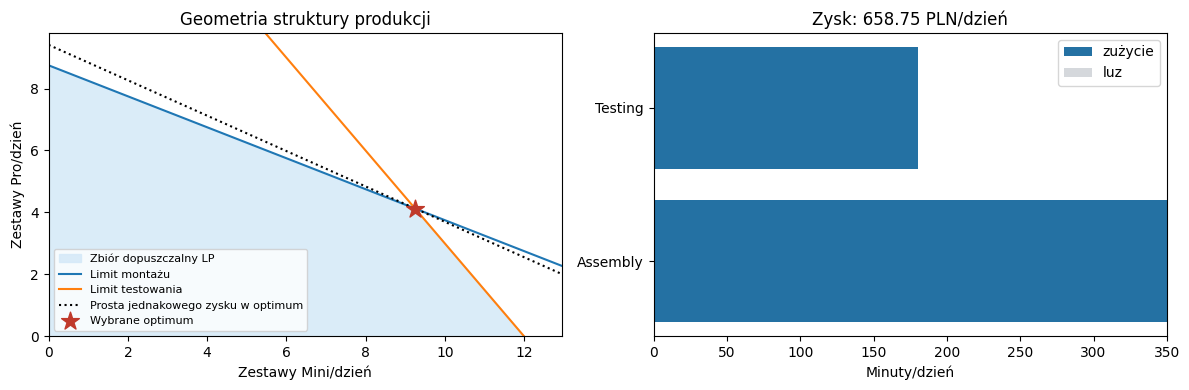

In [9]:
def assembly_experiment(assembly_min=350):
    """Wyświetl eksperyment z limitem montażu; zwróć None.

    assembly_min domyślnie wynosi 350 min/dzień; pozostałe dane zachowują
    wartości domyślne solve_product_mix. Korzysta ze wspólnego solvera,
    funkcji rysującej oraz globalnego display. Zawsze wypisuje status;
    tabele i wykres pokazuje tylko dla optimum. Wywołanie może być
    bezpośrednie albo pochodzić z suwaka montażu.
    """
    # Użyj limitu z kontrolki w nowym rozwiązaniu i sprawdź status przed wyświetlaniem.
    result = solve_product_mix(assembly_min=assembly_min)
    print("Status:", result["status"])
    if result["status"] == "Optimal":
        display(result["variables"])
        display(result["resources"])
        plot_product_mix(result)

# Wariant bez suwaka: zmień 350 i uruchom tę komórkę.
assembly_experiment(assembly_min=350)

In [10]:
# Dopasuj nazwę kontrolki do argumentu funkcji zwrotnej; puszczenie suwaka rozwiąże model raz.
assembly_slider = widgets.IntSlider(value=350, min=100, max=900, step=10,
                                   description="Montaż", continuous_update=False)
assembly_control = widgets.interact(assembly_experiment, assembly_min=assembly_slider)

interactive(children=(IntSlider(value=350, continuous_update=False, description='Montaż', max=900, min=100, st…

### Zadanie 4 — samodzielnie dodaj kontrolkę

DO ZROBIENIA: skopiuj `assembly_experiment`, dodaj argument `testing_min` i przekaż oba limity czasu do `solve_product_mix`. Dodaj drugi `IntSlider` do `widgets.interact`. Sprawdź, czy wywołanie funkcji bezpośrednio i takie same ustawienia suwaków dają ten sam wynik. Następnie dodaj kontrolkę `pro_profit` i zmień tytuł wykresu tak, aby pokazywał jej wartość.

**Przewidź → uruchom → wyjaśnij:** zwiększ `Assembly` z 350 do 800. Czy zysk rośnie w całym zakresie? Teraz zwiększ `Testing`: czy zmienia to aktywny zasób? Zapisz wyniki przed otwarciem gotowego panelu z wieloma kontrolkami.

### Pełny panel eksperymentów

Minimalne zamówienia mogą sprawić, że model nie ma rozwiązania dopuszczalnego. Funkcja zwrotna sprawdza status i objaśnia konieczny warunek dostępności zasobów zamiast rysować niepoprawne wartości. Ta sama funkcja obsługuje wariant bez kontrolek.

`mix_experiment(assembly_min=350, testing_min=180, pro_profit=70, min_mini=0, integer=False)` przyjmuje limity czasu w minutach/dzień, zysk Pro w PLN/zestaw, zamówienie Mini w zestawach/dzień i przełącznik całych zestawów. Zapisuje zamówienie jako `minimum={"Mini": min_mini}`, wywołuje solver, wypisuje status i albo objaśnia sprawdzenie zasobów, albo wyświetla sprawdzone tabele i wykres. Zwraca słownik rozwiązania do dalszej analizy. Ponowne użycie tej funkcji zapewnia zgodność bezpośredniego wywołania z nazwanymi argumentami i panelu kontrolek.

Status: Optimal | Ciągły LP


,kits_per_day,reduced_cost_PLN_per_kit
product,,
Mini,9.250,0.0
Pro,4.125,0.0


,used_min,available_min,slack_min,binding,shadow_PLN_per_min
resource,,,,,
Assembly,350.0,350.0,0.0,True,1.625
Testing,180.0,180.0,0.0,True,0.500


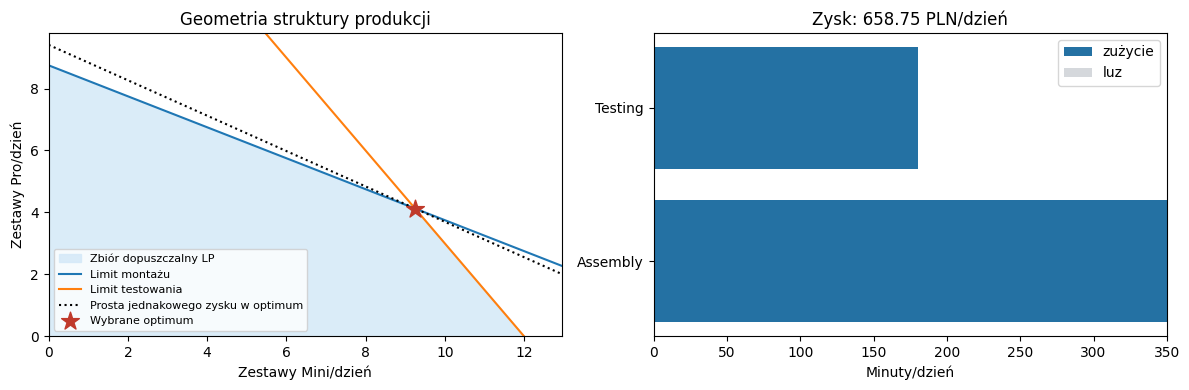

In [11]:
def mix_experiment(assembly_min=350, testing_min=180, pro_profit=70,
                   min_mini=0, integer=False):
    """Rozwiąż i wyświetl eksperyment produkcyjny; zwróć słownik wyników.

    Domyślne limity czasu to 350/180 min/dzień, pro_profit to 70 PLN/zestaw,
    min_mini to zero zestawów/dzień, a integer to False (ciągły LP).
    Korzysta z solve_product_mix, plot_product_mix i globalnego display.
    Zawsze wypisuje status i typ modelu. Dla statusu nieoptymalnego
    wyświetla konieczny warunek zasobów dla zamówienia Mini; dla optimum
    pokazuje tabele produkcji i zasobów oraz wykres. Struktura zwracanego
    słownika odpowiada solve_product_mix.
    """
    # Zapisz wartość kontrolki zamówienia Mini w słowniku zamówień solvera.
    result = solve_product_mix(assembly_min, testing_min, pro_profit,
                               minimum={"Mini": min_mini}, integer=integer)
    print("Status:", result["status"], "|", "Całkowitoliczbowy" if integer else "Ciągły LP")
    # Zakończ przed odczytem ilości lub rysowaniem, jeśli model nie ma optimum.
    if result["status"] != "Optimal":
        print(f"Samo zamówienie Mini wymaga {20*min_mini} minut montażu i {15*min_mini} minut testowania.")
        print("Porównaj te czasy z limitami; zmniejsz zamówienie lub dodaj wystarczająco dużo czasu.")
        return result
    display(result["variables"].round(4))
    display(result["resources"].round(4))
    plot_product_mix(result)
    return result

# Zawsze działa bez suwaków: zmień założenia i uruchom ponownie.
manual_result = mix_experiment(assembly_min=350, testing_min=180,
                               pro_profit=70, min_mini=0, integer=False)

### Połącz eksperyment z nazwanymi kontrolkami

`update_mix(**parameters)` to funkcja zwrotna odpowiedzialna za wyświetlanie: przekazuje słownik nazwanych wartości do `mix_experiment`, która rozwiązuje model, sprawdza status i tworzy tabele oraz wykresy. Zwraca `None`, więc obszar wyników nie wypisuje dodatkowo dużego słownika. Korzysta z istniejącej funkcji eksperymentu zamiast powielać model i jego kontrole.

Słownik `controls` przypisuje każdej nazwie argumentu jej kontrolkę. `interactive_output` odczytuje wartości kontrolek i wywołuje `update_mix` z tymi nazwami; `**parameters` przekazuje wartości jako argumenty nazwane. Jednostki i wartości domyślne odpowiadają `mix_experiment`. `VBox` układa kontrolki, a `live_output` przechwytuje wyniki wyświetlane przez funkcję.

In [12]:
# interactive_output łączy kilka nazwanych kontrolek z funkcją zwrotną.
# Funkcja pośrednicząca pomija zwrócony wynik, aby wyświetlić tylko nasze tabele i wykresy.
def update_mix(**parameters):
    """Przekaż nazwane wartości kontrolek do mix_experiment; zwróć None.

    parameters zawiera assembly_min/testing_min (min/dzień), pro_profit
    (PLN/zestaw), min_mini (zestawy/dzień) i integer (bool). Kontrolki
    zaczynają od 350, 180, 70, 0 i False; pominięte wartości przyjmują
    domyślne ustawienia eksperymentu. Korzysta z globalnego mix_experiment,
    którego status, tabele i wykresy pojawiają się w live_output.
    Celowo nie wypisuje dodatkowo zwróconego słownika wyników.
    """
    # Przy każdej zmianie kontrolki użyj tego samego eksperymentu ze sprawdzaniem statusu.
    mix_experiment(**parameters)

# Klucze to nazwy argumentów funkcji zwrotnej; kontrolki podają wartości we wskazanych jednostkach.
controls = {
    "assembly_min": widgets.IntSlider(value=350, min=100, max=900, step=10,
        description="Montaż", continuous_update=False),
    "testing_min": widgets.IntSlider(value=180, min=60, max=360, step=10,
        description="Testowanie", continuous_update=False),
    "pro_profit": widgets.IntSlider(value=70, min=20, max=140, step=5,
        description="Zysk Pro", continuous_update=False),
    "min_mini": widgets.IntSlider(value=0, min=0, max=20, step=1,
        description="Min. Mini", continuous_update=False),
    "integer": widgets.Checkbox(value=False, description="Całe zestawy"),
}
live_output = widgets.interactive_output(update_mix, controls)
display(widgets.VBox(list(controls.values())), live_output)

Output()

## 7. Wrażliwość: cała krzywa mówi więcej niż pojedyncza zmiana

Zmieniaj jedno założenie, pozostawiając pozostałe bez zmian. Każdy wiersz to nowa optymalizacja. Krzywa pokazuje zarówno zakres, w którym zasób ma wartość, jak i plateau, na którym inny zasób przejmuje rolę ograniczającą. To **analiza scenariuszy**; cena dualna opisuje tylko lokalną część krzywej.

,assembly_min,status,profit_PLN,Mini,Pro
0,100,Optimal,200.0,5.00,0.0
1,125,Optimal,250.0,6.25,0.0
2,150,Optimal,300.0,7.50,0.0
3,175,Optimal,350.0,8.75,0.0
4,200,Optimal,400.0,10.00,0.0


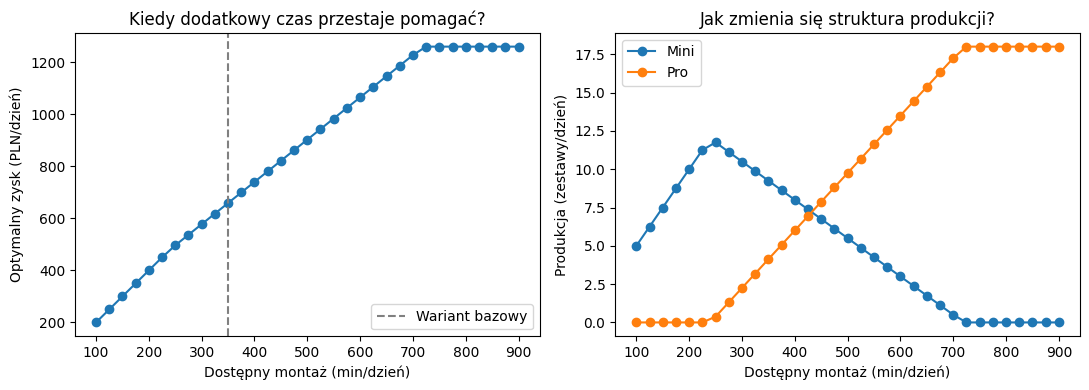

In [13]:
# Rozwiąż osobno każdy limit czasu; porównaj zysk i produkcję na wspólnych osiach.
sweep_rows = []
for assembly_minutes in range(100, 901, 25):
    result = solve_product_mix(assembly_min=assembly_minutes)
    sweep_rows.append({"assembly_min": assembly_minutes, "status": result["status"],
                       "profit_PLN": result["profit"], **result["quantities"]})
sweep = pd.DataFrame(sweep_rows)
display(sweep.head())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(sweep["assembly_min"], sweep["profit_PLN"], "o-")
axes[0].axvline(350, color="gray", linestyle="--", label="Wariant bazowy")
axes[0].set(xlabel="Dostępny montaż (min/dzień)", ylabel="Optymalny zysk (PLN/dzień)",
            title="Kiedy dodatkowy czas przestaje pomagać?")
axes[0].legend()
for product in PRODUCTS:
    axes[1].plot(sweep["assembly_min"], sweep[product], "o-", label=product)
axes[1].set(xlabel="Dostępny montaż (min/dzień)", ylabel="Produkcja (zestawy/dzień)",
            title="Jak zmienia się struktura produkcji?")
axes[1].legend()
plt.tight_layout()
plt.show()

### Sprawdź cenę dualną przez ponowne rozwiązanie

CBC udostępnia cenę dualną wiersza LP jako `.pi`. Porównaj przewidywanie `cena dualna × dodatkowe minuty` z rzeczywistą zmianą funkcji celu. W wariancie bazowym oba ograniczenia zasobów są aktywne. Po dużej zmianie inne ograniczenie może decydować o planie. Zerowa cena dualna może wystąpić nawet przy aktywnym wierszu w zdegenerowanym LP; nie utożsamiaj „aktywnego” z „wartościowym”.

In [14]:
# Porównaj lokalne przewidywanie ceny dualnej z rzeczywistymi małymi i dużymi zmianami.
dual = baseline["resources"].loc["Assembly", "shadow_PLN_per_min"]
sensitivity_rows = []
for extra_min in [1, 10, 500]:
    changed = solve_product_mix(assembly_min=350 + extra_min)
    sensitivity_rows.append({
        "extra_assembly_min": extra_min,
        "dual_prediction_PLN": None if dual is None else dual * extra_min,
        "actual_profit_gain_PLN": changed["profit"] - baseline["profit"],
    })
display(pd.DataFrame(sensitivity_rows))

,extra_assembly_min,dual_prediction_PLN,actual_profit_gain_PLN
0,1,1.625,1.625
1,10,16.250,16.250
2,500,812.500,601.250


### Zadanie 5 — decyzja o zakupie dodatkowego czasu

DO ZROBIENIA: oferta A daje 10 dodatkowych minut montażu za 15 PLN/dzień; oferta B daje 500 minut za 750 PLN/dzień. Odejmij koszt każdego zakupu od przyrostu zysku uzyskanego po **ponownym rozwiązaniu**. Czy przyjmiesz którąś ofertę? Powtórz sprawdzenie różnicą skończoną dla jednej dodatkowej minuty testowania i wyjaśnij jednostki ceny dualnej. Dlaczego ekstrapolowanie ceny dualnej montażu na ofertę B jest mylące?

### Rozszerzenie: koszt zredukowany i alternatywne optima

`.dj` zmiennej LP to jej **koszt zredukowany**. W modelu maksymalizacyjnym, gdy zmienna jest na dolnej granicy, ujemny koszt zredukowany opisuje krańcową stratę wynikającą z wymuszenia udziału tej zmiennej w planie przy ponownej optymalizacji pozostałych zmiennych. Jego wartość bezwzględna określa poprawę współczynnika funkcji celu potrzebną, aby zmienna mogła stać się atrakcyjna w obrębie obecnej bazy LP. Dodatnie zmienne bazowe zwykle mają zerowy koszt zredukowany. Konwencje granic i degeneracja wymagają ostrożności, dlatego sprawdź interpretację przez zmianę współczynnika i ponowne rozwiązanie.

Zmniejsz zysk Pro do 20 PLN/zestaw. DO ZROBIENIA: wyjaśnij, dlaczego Pro nie jest produkowany, sprawdź jego koszt zredukowany, a następnie stopniowo zwiększaj zysk. Przy 80 PLN/zestaw oba produkty przynoszą 2 PLN na minutę montażu: sprawdź, czy `(Mini, Pro) = (0, 8.75)` oraz `(6.25, 5.625)` są optymalnymi dopuszczalnymi planami LP. Solver podaje jedno optimum, nie listę wszystkich alternatywnych optimów.

In [15]:
# Zmień jeden współczynnik zysku, aby zbadać koszty zredukowane i alternatywne optima LP.
low_pro_profit = solve_product_mix(pro_profit=20)
display(low_pro_profit["variables"])
alternate_optimum = solve_product_mix(pro_profit=80)
print("Jedno optimum przy zysku Pro równym 80:", alternate_optimum["quantities"],
      "| zysk", alternate_optimum["profit"])

,kits_per_day,reduced_cost_PLN_per_kit
product,,
Mini,12.0,-0.000000
Pro,0.0,-6.666667


Jedno optimum przy zysku Pro równym 80: {'Mini': 0.0, 'Pro': 8.75} | zysk 700.0


## 8. Całe zestawy: decyzje ciągłe i całkowitoliczbowe

**Relaksacja LP** pozwala na ilości ułamkowe; model całkowitoliczbowy ogranicza je do liczb całkowitych. Przy maksymalizacji relaksacja daje **górne oszacowanie** zysku całkowitoliczbowego. Zaokrąglenie do najbliższej liczby może przekroczyć zasoby. Zaokrąglenie w dół może dać plan dopuszczalny, ale nieoptymalny. Rozwiąż model całkowitoliczbowy, aby wybrać najlepszy plan całych zestawów; ceny dualne LP nie są miarami krańcowymi modelu całkowitoliczbowego.

,plan,Mini,Pro,profit_PLN
0,Relaksacja LP,9.25,4.125,658.75
1,Zaokrąglenie LP w dół,9.00,4.000,640.00
2,Optimum całkowitoliczbowe,9.00,4.000,640.00


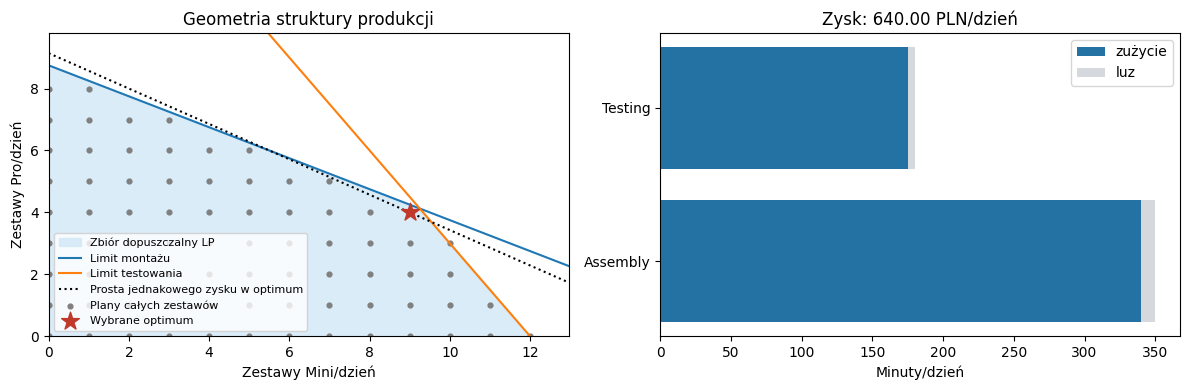

Luka całkowitoliczbowa (PLN): 18.75


In [16]:
# Porównaj zaokrąglenie podzielnego planu z bezpośrednią optymalizacją całych zestawów.
integer_result = solve_product_mix(integer=True)
floor_plan = {p: int(np.floor(baseline["quantities"][p])) for p in PRODUCTS}
floor_profit = sum(PROFIT[p] * floor_plan[p] for p in PRODUCTS)
comparison = pd.DataFrame([
    {"plan": "Relaksacja LP", **baseline["quantities"], "profit_PLN": baseline["profit"]},
    {"plan": "Zaokrąglenie LP w dół", **floor_plan, "profit_PLN": floor_profit},
    {"plan": "Optimum całkowitoliczbowe", **integer_result["quantities"], "profit_PLN": integer_result["profit"]},
])
display(comparison)
plot_product_mix(integer_result)
print("Luka całkowitoliczbowa (PLN):", baseline["profit"] - integer_result["profit"])

## 9. Brak rozwiązania dopuszczalnego też wymaga interpretacji

Minimalne zamówienie 13 zestawów Mini wymaga 195 minut testowania, zanim zaczniemy produkować jakikolwiek zestaw Pro; dostępne jest tylko 180 minut. To bezpośrednie wyjaśnienie niedopuszczalności. Zwiększenie samego czasu montażu nie naprawi problemu.

In [17]:
# Zachowaj zamówienie i zwiększ dostępność stanowiska, które rzeczywiście ogranicza plan.
impossible_order = solve_product_mix(minimum={"Mini": 13})
print("Zamówienie 13 zestawów Mini:", impossible_order["status"])
repaired_order = solve_product_mix(testing_min=200, minimum={"Mini": 13})
print("Po zwiększeniu czasu testowania do 200:", repaired_order["status"])
if repaired_order["status"] == "Optimal":
    display(repaired_order["resources"])

Zamówienie 13 zestawów Mini: Infeasible
Po zwiększeniu czasu testowania do 200: Optimal


,used_min,available_min,slack_min,binding,shadow_PLN_per_min
resource,,,,,
Assembly,280.0,350.0,70.0,False,-0.0
Testing,200.0,200.0,0.0,True,7.0


## 10. Własne badanie i rekomendacja

Prowadź dziennik eksperymentów. Zmieniaj po jednym założeniu, zanim zaczniesz łączyć zmiany.

| Scenariusz | Przewidywanie | Zmienione założenie i jednostki | Status | Struktura produkcji | Zysk | Luz | Wyjaśnienie |
|:--|:--|:--|:--|:--|:--|:--|:--|
| Wariant bazowy | | | | | | | |
| Więcej montażu | | | | | | | |
| Więcej testowania | | | | | | | |
| Zmiana ceny Pro | | | | | | | |
| Wymagane zamówienie | | | | | | | |

DO ZROBIENIA: oddaj notebook zawierający:

1. LP zapisany symbolicznie oraz znaczenie i jednostki każdej zmiennej.
2. Zmodyfikowany wykres zasobów i samodzielnie zbudowane dwa suwaki.
3. Co najmniej cztery zmienione scenariusze, w tym jeden niedopuszczalny i sposób jego naprawy.
4. Jedno przewidywanie na podstawie ceny dualnej sprawdzone ponownym rozwiązaniem oraz jedną dużą zmianę, dla której to przewidywanie zawodzi.
5. Rekomendowany plan **całych zestawów na dziś**, jego zysk i luz ograniczeń zasobów, a także ofertę dodatkowego czasu, którą przyjmiesz lub odrzucisz. Wskaż jedno ograniczenie przyjętych założeń.

**Połączenie z dalszymi laboratoriami:** laboratorium 2 minimalizuje koszt mieszanki przy wymaganiach jakościowych, stosując równości i nadwyżkę w ograniczeniach `>=`. Laboratorium 3 rozdziela przesyłki i tnie całkowitoliczbową liczbę prętów. Laboratorium 4 dodaje czasy rozpoczęcia i decyzje binarne, aby zaplanować pracę wspólnych stanowisk.

Materiały do dalszej lektury: [kod źródłowy i wydania PuLP 3.x](https://github.com/coin-or/pulp), [szybki start z Matplotlib](https://matplotlib.org/stable/users/explain/quick_start.html), [ipywidgets: korzystanie z Interact](https://ipywidgets.readthedocs.io/en/latest/examples/Using%20Interact.html).